In [14]:
import time
import itertools
import numpy as np
import pandas as pds
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import ClassifierMixin, BaseEstimator, clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

In [15]:
SEED = 83
RUN_NESTED = True

train_raw = pds.read_csv("train_data.csv")
test_raw = pds.read_csv("test_data.csv")

y = (train_raw["Class"] == 2).astype(int) # Convert class 2 to 1 and class 1 to 0
X = train_raw.drop(columns="Class") # Drop the target value column from training dataset

In [16]:
skewed_cols = ["CLimit", "Open", "Revolving", "TransAmt", "TransCt"]

def add_feats(df):
    df = df.copy()
    df["AvgTransAmt"] = df["TransAmt"] / (df["TransCt"] + 1)
    df["RevolvingRatio"] = df["Revolving"] / (df["CLimit"] + 1)
    for c in skewed_cols + ["AvgTransAmt"]:
        df["log_" + c] = np.log1p(df[c].clip(lower=0))
    return df

X = add_feats(X)
test_data = add_feats(test_raw)

categorical_cols = ["Gender", "Education", "Marital", "Income", "KCategory", "Group"]
numerical_cols = [col for col in X.columns if col  not in categorical_cols]
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

def make_prep(cols):
    cat = [c for c in categorical_cols if c in cols]
    num = [n for n in numerical_cols if n in cols]
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat), 
                              ("num", StandardScaler(), num)])

In [17]:
single_auc = pds.Series({c: roc_auc_score(y, X[c]) for c in numerical_cols}).sub(0.5).abs().sort_values(ascending=False)
print("|Auc - 0.5| of each numeric feature on its own:")
print(single_auc.round(3).to_string())

def quick_svm_auc(cols):
    p = Pipeline([("prep", make_prep(cols)), ("model", SVC(C=2, gamma=0.03, kernel="rbf", random_state=SEED))])
    return cross_val_score(p, X[cols], y, cv=cv, scoring="roc_auc", n_jobs=-1).mean()

all_cols = list(X.columns)
base_auc = quick_svm_auc(all_cols)
loo = pds.Series({c: quick_svm_auc([k for k in all_cols if k != c]) - base_auc for c in all_cols}).sort_values()
print(f"\nSVM AUC with all {len(all_cols)} features: {base_auc:.4f}\nChange in AUC when a feature is dropped (positive means feature was hurting)")
print(loo.round(4).to_string())

|Auc - 0.5| of each numeric feature on its own:
AvgTransAmt        0.299
log_AvgTransAmt    0.299
log_TransCt        0.299
TransCt            0.299
Ct_41              0.251
ContactNum         0.146
Inactive           0.123
Relationship       0.115
Essential          0.029
Dependent          0.021
log_Open           0.016
Open               0.016
Revolving          0.013
log_Revolving      0.013
RevolvingRatio     0.012
TransAmt           0.011
log_TransAmt       0.011
Utilization        0.009
Importance         0.008
Customer_Age       0.006
DropLevel          0.004
onBook             0.003
MustHave           0.002
Amt_41             0.002
CLimit             0.001
log_CLimit         0.001

SVM AUC with all 32 features: 0.9162
Change in AUC when a feature is dropped (positive means feature was hurting)
Relationship      -0.0216
Ct_41             -0.0180
Inactive          -0.0085
ContactNum        -0.0043
log_Open          -0.0040
AvgTransAmt       -0.0038
Marital           -0.0036
Trans

In [18]:
NOISE_COLS = ["CLimit", "Importance", "Revolving", "MustHave", "Utilization", "Amt_41", "Group", "Essential", "DropLevel"]
WEAK_COLS = ["Income", "Open", "Dependent", "KCategory", "TransAmt", "Education"]
FEATURE_SETS = {
    "all": all_cols,
    "core": [c for c in all_cols if c not in NOISE_COLS],
    "compact": [c for c in all_cols if c not in NOISE_COLS + WEAK_COLS],
}
for k, cols in FEATURE_SETS.items():
    print(f"{k:.8s} ({len(cols):2d} cols) SVM CV AUC = {quick_svm_auc(cols):.4f}")

all (32 cols) SVM CV AUC = 0.9162
core (23 cols) SVM CV AUC = 0.9266
compact (17 cols) SVM CV AUC = 0.9289


In [19]:
class SeedAvgMLP(ClassifierMixin, BaseEstimator):
    def __init__(self, hidden_layer_sizes=(256, 128), alpha=1, n_seeds=5):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.alpha = alpha
        self.n_seeds = n_seeds

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.nets_ = [MLPClassifier(hidden_layer_sizes=self.hidden_layer_sizes, alpha=self.alpha, early_stopping=True, max_iter=500, 
                                    random_state=SEED + s).fit(X, y) for s in range(self.n_seeds)]
        return self

    def predict_proba(self, X):
        return np.mean([n.predict_proba(X) for n in self.nets_], axis=0)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]

In [20]:
models = {
    "logreg": (LogisticRegression(solver="liblinear", max_iter=2000),
               {"model__C": [0.1, 1, 50, 100, 150, 200], "model__l1_ratio": [0, 1]}),
    "svm": (SVC(kernel="rbf"), 
            {"model__C": [1, 2, 3, 5, 10], "model__gamma": ["scale", 0.01, 0.02, 0.03, 0.05, 0.1]}),
    "mlp": (SeedAvgMLP(n_seeds=3),
            {"model__hidden_layer_sizes": [(128, 64), (256, 128), (128, 64, 32), (256, 128, 64)],
              "model__alpha": [0.003, 0.03, 0.3, 1, 2]}),
    "tree": (DecisionTreeClassifier(random_state=SEED),
             {"model__max_depth": [5, 8, 10, 25, None], "model__min_samples_leaf": [2, 25, 50]}),
}
score_method = {k: ("decision_function" if k == "svm" else "predict_proba") for k in models}

FEATURE_SET = {"logreg": "core", "svm": "compact", "mlp": "core", "tree": "core"}

def make_pipe(name, est):
    cols = FEATURE_SETS[FEATURE_SET[name]]
    return Pipeline([("prep", make_prep(cols)), ("model", est)])

def get_score(est, Xd, method):
    out = getattr(est, method)(Xd)
    return out[:, 1] if out.ndim == 2 else out

In [21]:
best, searches = {}, {}

for name, (model, grid) in models.items():
    t = time.time()
    pipe = make_pipe(name, model)
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, verbose=2, n_jobs=-1, refit=True)
    gs.fit(X, y)
    best[name] = gs.best_estimator_
    searches[name] = gs
    if name == "mlp":
        best[name] = clone(gs.best_estimator_).set_params(model__n_seeds=5).fit(X, y)
    print(f"{name:7s}: CV AUC = {gs.best_score_:.4f}, params = {gs.best_params_}  ({time.time()-t:.0f}s)")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
logreg : CV AUC = 0.9040, params = {'model__C': 100, 'model__l1_ratio': 1}  (16s)
Fitting 5 folds for each of 30 candidates, totalling 150 fits
svm    : CV AUC = 0.9321, params = {'model__C': 10, 'model__gamma': 0.03}  (29s)
Fitting 5 folds for each of 20 candidates, totalling 100 fits
mlp    : CV AUC = 0.9329, params = {'model__alpha': 0.03, 'model__hidden_layer_sizes': (256, 128)}  (206s)
Fitting 5 folds for each of 15 candidates, totalling 75 fits
tree   : CV AUC = 0.9088, params = {'model__max_depth': 8, 'model__min_samples_leaf': 50}  (2s)


In [22]:
for name, gs in searches.items():
    print(name)
    for p, vals in gs.param_grid.items():
        print("  ", p, "best =", gs.best_params_[p], "| grid =", vals)

logreg
   model__C best = 100 | grid = [0.1, 1, 50, 100, 150, 200]
   model__l1_ratio best = 1 | grid = [0, 1]
svm
   model__C best = 10 | grid = [1, 2, 3, 5, 10]
   model__gamma best = 0.03 | grid = ['scale', 0.01, 0.02, 0.03, 0.05, 0.1]
mlp
   model__hidden_layer_sizes best = (256, 128) | grid = [(128, 64), (256, 128), (128, 64, 32), (256, 128, 64)]
   model__alpha best = 0.03 | grid = [0.003, 0.03, 0.3, 1, 2]
tree
   model__max_depth best = 8 | grid = [5, 8, 10, 25, None]
   model__min_samples_leaf best = 50 | grid = [2, 25, 50]


In [23]:
out_of_fold = {}
for name in models:
    out_of_fold[name] = cross_val_predict(clone(best[name]), X, y, cv=cv, method=score_method[name], n_jobs=-1)
    out_of_fold[name] = out_of_fold[name][:, 1] if out_of_fold[name].ndim == 2 else out_of_fold[name]

def rank01(s):
    return rankdata(s) / len(s)

single = {n: roc_auc_score(y, out_of_fold[n]) for n in models}
rows = [((n,), a) for n, a in single.items()]
blend_models = ["svm", "mlp", "tree"]
for k in range(2, len(blend_models) + 1):
    for combo in itertools.combinations(models, k):
        rows.append((combo, roc_auc_score(y, np.mean([rank01(out_of_fold[n]) for n in combo], axis=0))))
blend_table = pds.DataFrame(rows, columns=["models", "oof_auc"]).sort_values("oof_auc", ascending=False)
blend_table["models"] = blend_table["models"].apply(lambda t: "+".join(t))
print(blend_table.head(12).to_string(index=False))
best_combo = blend_table.iloc[0]["models"].split("+")
print("\nChosen:", best_combo)

         models  oof_auc
   svm+mlp+tree 0.939750
        svm+mlp 0.937051
       svm+tree 0.935582
logreg+svm+tree 0.935325
       mlp+tree 0.934587
 logreg+svm+mlp 0.933371
logreg+mlp+tree 0.932266
            mlp 0.932009
            svm 0.931907
     logreg+svm 0.929796
     logreg+mlp 0.924850
    logreg+tree 0.923937

Chosen: ['svm', 'mlp', 'tree']


In [24]:
nested = {}
if RUN_NESTED:
    outer = StratifiedKFold(5, shuffle=True, random_state=SEED + 1)
    inner = StratifiedKFold(5, shuffle=True, random_state=SEED + 2)
    for name, (est, grid) in models.items():
        t = time.time()
        pipe = make_pipe(name, est)
        gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=inner, verbose=2, n_jobs=-1)
        nested[name] = cross_val_score(gs, X, y, cv=outer, scoring="roc_auc")
        print(f"{name:7s} nested AUC = {nested[name].mean():.4f} +/- {nested[name].std():.4f}  ({time.time()-t:.0f}s)")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Fitting 5 folds for each of 12 candidates, totalling 60 fits
logreg  nested AUC = 0.9049 +/- 0.0036  (63s)
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Fitting 5 folds for each of 30 candidates, totalling 150 fits
svm     nested AUC = 0.9324 +/- 0.0060  (108s)
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Fitting 5 folds for each of 20 candidates, t

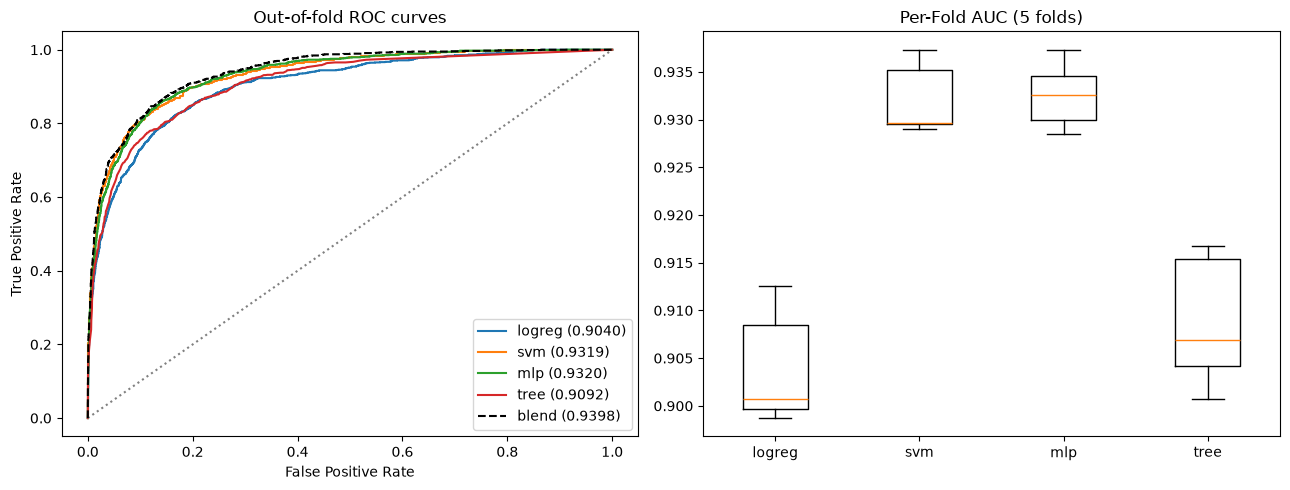

        grid-search CV  nested CV
logreg          0.9040     0.9049
svm             0.9321     0.9324
mlp             0.9329     0.9330
tree            0.9088     0.9010


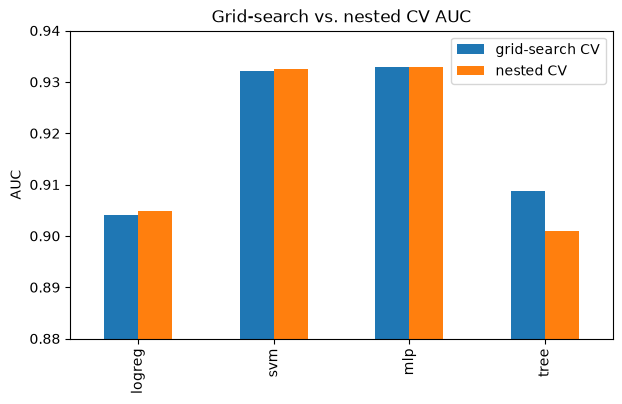

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n in models:
    fpr, tpr, _ = roc_curve(y, out_of_fold[n])
    ax[0].plot(fpr, tpr, label=f"{n} ({single[n]:.4f})")
bl = np.mean([rank01(out_of_fold[n]) for n in best_combo], axis=0)
fpr, tpr, _ = roc_curve(y, bl)
ax[0].plot([0, 1], [0, 1], ":", color="gray")
ax[0].plot(fpr, tpr, "k--", label=f"blend ({roc_auc_score(y, bl):.4f})")
ax[0].set_xlabel("False Positive Rate")
ax[0].set_ylabel("True Positive Rate")
ax[0].set_title("Out-of-fold ROC curves")
ax[0].legend()

fold_scores = np.array([[roc_auc_score(y.iloc[te], out_of_fold[n][te]) for _, te in cv.split(X, y)] for n in models])
ax[1].boxplot(fold_scores.T, tick_labels=list(models))
ax[1].set_title("Per-Fold AUC (5 folds)")
plt.tight_layout()
plt.show()

if RUN_NESTED:
    cmp_ = pds.DataFrame({"grid-search CV": {n: searches[n].best_score_ for n in models},
                         "nested CV": {n: nested[n].mean() for n in models}})
    print(cmp_.round(4))
    cmp_.plot.bar(figsize=(7, 4), ylim=(0.88, 0.94), title="Grid-search vs. nested CV AUC")
    plt.ylabel("AUC")
    plt.show()

In [26]:
test_scores = []
for n in best_combo:
    s = get_score(best[n], test_data, score_method[n])
    test_scores.append(rankdata(s) / len(s))
final = np.mean(test_scores, axis=0)

out = pds.DataFrame(final)
out.to_csv("HW4_test_output.csv", header=False, index=False)
chk = pds.read_csv("HW4_test_output.csv", header=None)
print(chk.shape, "min/max:", chk[0].min().round(4), chk[0].max().round(4))
assert chk.shape == (len(test_raw), 1)

(2532, 1) min/max: 0.034 0.9976


In [ ]:
def heat(ax, name, row, col):
    r = pds.DataFrame(searches[name].cv_results)
    r["row"] = r["param_" + row].astype(str)
    r["col"] = r["param_" + col].astype(str)
    piv = r.pivot_table(index="row", columns="col", values="mean_test_score", sort=False)
    im = ax.imshow(piv.values, cmap="coolwarm", aspect="auto")
    ax.set_xticks(range(piv.shape[1]))
    ax.set_xticklabels(piv.columns, rotation=45)
    ax.set_yticks(range(piv.shape[0]))
    ax.set_yticklabels(piv.index)
    for (a, b), v in np.ndenumerate(piv.values):
        ax.text(b, a, f"{v:.4f}", ha="center", va="center", color="w", fontsize=8)
        ax.set_title(f"{name}: CV AUC")
        ax.set_xlabel(col.replace("model__", ""))
        ax.set_ylabel(row.replace("model__", ""))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
heat(ax[0], "svm", "model__C", "model__gamma")
heat(ax[1], "mlp", "model__hidden_layer_sizes", "model__alpha")
heat(ax[2], "tree", "model__max_depth", "model__min_samples_leaf")
plt.tight_layout()
plt.show()